# Part 3: Acceptability degree spaces

We compute the weighted h-categorizer scores, then plot their convex hull and
density for different argumentation frameworks. Each run uses 100,000 random
weight vectors. An attack `(a, b)` means that a attacks b.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, cKDTree
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

N = 100000
EPSILON = 1e-8
SEEDS = [2026, 2027, 2028, 2029, 2030]
OUT = Path("results")
OUT.mkdir(exist_ok=True)

## 1. Weighted h-categorizer

Start with $x=w$, then update all scores at the same time:

$$x_i^{new}=\frac{w_i}{1+\sum_{j\text{ attacks }i}x_j}.$$

Stop when the largest change is below $\epsilon$. The iteration limit prevents
an endless loop. The matrix stores attacks as `M[target, attacker]`.

In [2]:
def h_categorizer(arguments, attacks, weights, epsilon=EPSILON):
    # Map each argument to a unique index and ensure arguments are distinct
    index = {a: i for i, a in enumerate(arguments)}
    if not arguments or len(index) != len(arguments):
        raise ValueError("Arguments must be non empty and distinct")
    
    # Build adjacency matrix where M[target, attacker] = 1
    M = np.zeros((len(arguments), len(arguments)))
    for source, target in attacks:
        M[index[target], index[source]] = 1
    
    # Validate weight dimensions and ensure values lie in [0, 1]
    w = np.asarray(weights, dtype=float)
    if w.ndim not in (1, 2) or w.shape[-1] != len(arguments) or w.size == 0:
        raise ValueError("Weights must match the number of arguments")
    if not np.isfinite(w).all() or np.any((w < 0) | (w > 1)):
        raise ValueError("Weights must be in [0, 1]")
    if not np.isfinite(epsilon) or epsilon <= 0:
        raise ValueError("epsilon must be positive and finite")
    
    x = w.copy()
    for iteration in range(1, 10_001):
        new_x = w / (1 + x @ M.T) # x @ M.T sums the attackers scores for each target
        if np.max(np.abs(new_x - x)) <= epsilon:
            return new_x, iteration
        x = new_x
    raise RuntimeError("The iteration did not converge")

In [3]:
# A few cases where the answer can be calculated directly
np.testing.assert_allclose(h_categorizer(["a", "b"], [], [0.2, 0.5])[0], [0.2, 0.5])
example, _ = h_categorizer(["a", "b"], [("a", "b")], [0.2, 0.5])
np.testing.assert_allclose(example, [0.2, 0.5 / 1.2])

self_score, _ = h_categorizer(["a"], [("a", "a")], [1.0])
np.testing.assert_allclose(self_score, [(np.sqrt(5) - 1) / 2], atol=1e-8)
print("Checks passed. Example a -> b:", example)

Checks passed. Example a -> b: [0.2        0.41666667]


## 2(a–b). Frameworks and sampling

Each row of weights is sampled uniformly from the unit cube. The function also
accepts a single weight vector. The same seed is used across frameworks so the
inputs are comparable.

In [4]:
frameworks = {
    "No attacks": (["a", "b"], []),
    "One attack": (["a", "b"], [("a", "b")]),
    "Mutual attack": (["a", "b"], [("a", "b"), ("b", "a")]),
    "Self-attack": (["a", "b"], [("a", "a")]),
    "Chain": (["a", "b", "c"], [("a", "b"), ("b", "c")]),
    "Cycle": (["a", "b", "c"], [("a", "b"), ("b", "c"), ("c", "a")]),
    "Complete": (["a", "b", "c"], [(a, b) for a in "abc" for b in "abc" if a != b]),
}

def sample(arguments, attacks, seed):
    weights = np.random.default_rng(seed).random((N, len(arguments)))
    return h_categorizer(arguments, attacks, weights)

points, hulls, rows = {}, {}, []
for name, (arguments, attacks) in frameworks.items():
    points[name], iterations = sample(arguments, attacks, SEEDS[0])
    hulls[name] = ConvexHull(points[name])
    rows.append([name, len(arguments), iterations, hulls[name].volume, points[name].mean()])

summary = pd.DataFrame(rows, columns=["Framework", "Arguments", "Iterations", "Hull measure", "Mean score"])
summary.to_csv(OUT / "baseline.csv", index=False)
display(summary.round(5))

,Framework,Arguments,Iterations,Hull measure,Mean score
0,No attacks,2,1,0.99965,0.49834
1,One attack,2,2,0.74585,0.42195
2,Mutual attack,2,20,0.61590,0.37991
3,Self-attack,2,20,0.61775,0.42295
4,Chain,3,3,0.58965,0.40827
5,Cycle,3,20,0.47031,0.37157
6,Complete,3,27,0.30171,0.31874


## 2(c–d). Convex hulls and heat maps

For two arguments, colour shows histogram density: bin count divided by sample
size and bin area. The black line is the convex hull. Grey cells have no samples.
All panels use the same colour scale, with 48 bins per axis.

The hull can contain impossible scores. For example, with $a\to b$, the points
$(0,1)$ and $(1,0.5)$ are attainable, but their midpoint $(0.5,0.75)$ would require
$w_b=0.75(1+0.5)=1.125>1$. More samples cannot remove this convexification effect.

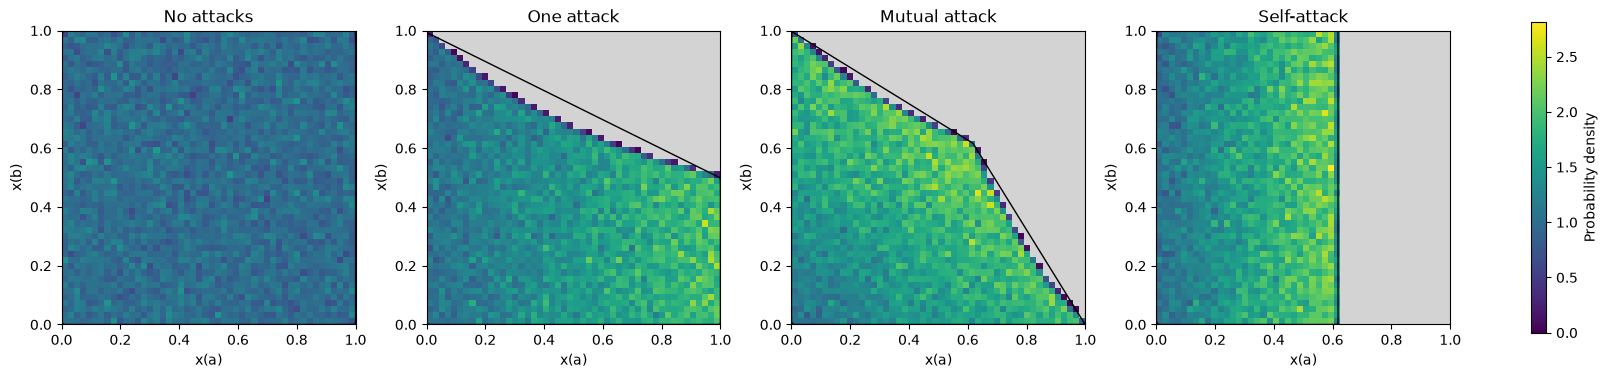

In [5]:
names_2d = [name for name, x in points.items() if x.shape[1] == 2]
histograms = {name: np.histogram2d(*points[name].T, bins=48, range=[(0, 1)] * 2, density=True)
              for name in names_2d}
vmax = max(h[0].max() for h in histograms.values())
fig, axes = plt.subplots(1, len(names_2d), figsize=(4 * len(names_2d), 4), layout="constrained", squeeze=False)

for ax, name in zip(axes.flat, names_2d):
    density, xe, ye = histograms[name]
    cmap = plt.colormaps["viridis"].copy()
    cmap.set_bad("lightgrey") # Render empty bins in light grey
    
    image = ax.pcolormesh(xe, ye, np.ma.masked_equal(density.T, 0), cmap=cmap, vmin=0, vmax=vmax)

    # Close the convex hull polygon by appending the first vertex at the end
    boundary = points[name][np.r_[hulls[name].vertices, hulls[name].vertices[0]]]
    ax.plot(*boundary.T, color="black", lw=1)
    ax.set(title=name, xlabel="x(a)", ylabel="x(b)", xlim=(0, 1), ylim=(0, 1), aspect="equal"
          )
fig.colorbar(image, ax=axes.ravel().tolist(), label="Probability density", shrink=0.8)
fig.savefig(OUT / "density_2d.png", dpi=150)
plt.show()

For three arguments, we display the full hull. Its faces are coloured using the
300 nearest samples to each face centre, estimating density per unit volume.
This estimate is biased near boundaries and can smooth across unattainable gaps.
The colours describe nearby sample density, not the probability of a hull face.

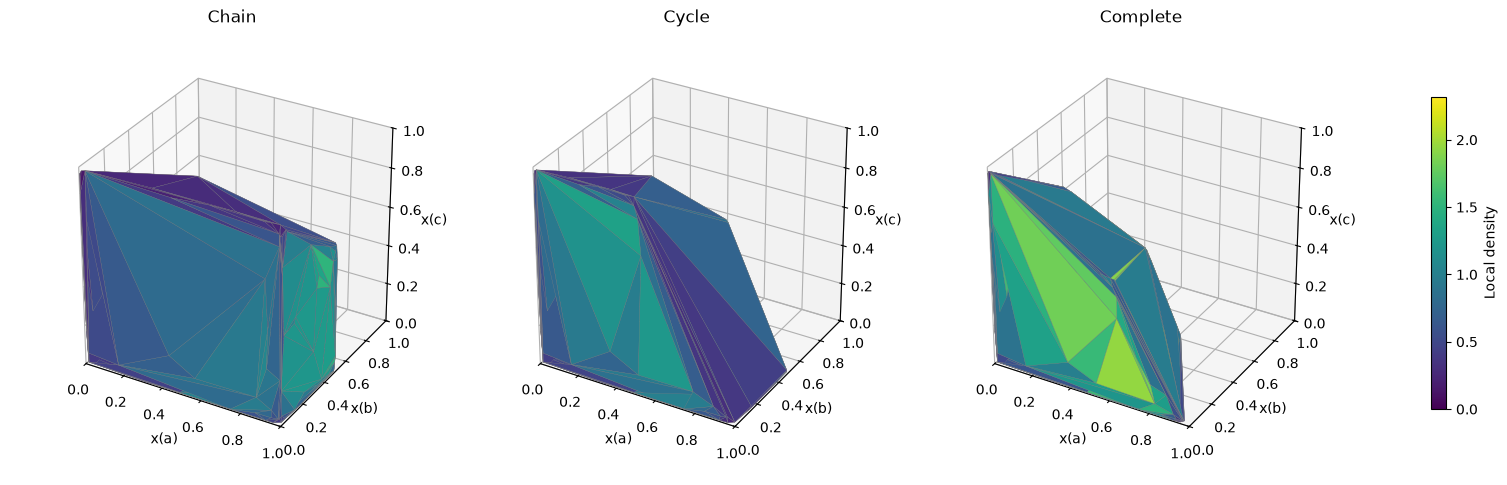

In [6]:
names_3d = [name for name, x in points.items() if x.shape[1] == 3]
faces, densities = {}, {}
for name in names_3d:
    # Extract the triangular faces of the 3D convex hull
    faces[name] = points[name][hulls[name].simplices]

    # Find the distance from each face centroid to its 300th nearest sample point
    radius = cKDTree(points[name]).query(faces[name].mean(axis=1), k=[300])[0][:, 0]

    # Estimate local density per unit volume using the 3D sphere volume
    densities[name] = 300 / (N * (4 * np.pi / 3) * radius**3)
    
norm = plt.Normalize(0, max(d.max() for d in densities.values()))
fig = plt.figure(figsize=(5 * len(names_3d), 5), layout="constrained")
axes = []
for i, name in enumerate(names_3d):
    ax = fig.add_subplot(1, len(names_3d), i + 1, projection="3d")
    ax.add_collection3d(Poly3DCollection(faces[name], facecolors=plt.cm.viridis(norm(densities[name])),
                                        edgecolors="grey", linewidths=0.2))
    ax.set(title=name, xlabel="x(a)", ylabel="x(b)", zlabel="x(c)", xlim=(0, 1), ylim=(0, 1), zlim=(0, 1))
    ax.set_box_aspect((1, 1, 1), zoom=0.85)
    axes.append(ax)
    
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=axes, label="Local density", shrink=0.65)
fig.savefig(OUT / "density_3d.png", dpi=150)
plt.show()

## Re-sampling

Repeat each experiment with four other seeds. On a fixed grid, compare the bin
proportions using total variation: $\mathrm{TV}(p,q)=\frac12\sum_b|p_b-q_b|$.
Zero means identical histograms. We test 8, 16 and 32 bins per coordinate.
The table uses 16 bins and also shows how much the hull area or volume varies.

In [7]:
def bin_proportions(x, bins):
    counts, _ = np.histogramdd(x, bins=bins, range=[(0, 1)] * x.shape[1])
    return counts / len(x)

comparisons, measures = [], []
for name, (arguments, attacks) in frameworks.items():
    measures.append([name, SEEDS[0], hulls[name].volume])
    for seed in SEEDS[1:]:
        x, _ = sample(arguments, attacks, seed)
        measures.append([name, seed, ConvexHull(x).volume])
        for bins in [8, 16, 32]:
            # Compute Total Variation (TV) distance against the baseline run (SEEDS[0])
            tv = np.abs(bin_proportions(x, bins) - bin_proportions(points[name], bins)).sum() / 2
            comparisons.append([name, seed, bins, tv])
            
stability = pd.DataFrame(comparisons, columns=["Framework", "Seed", "Bins", "TV"])
measures = pd.DataFrame(measures, columns=["Framework", "Seed", "Hull measure"])
table = stability[stability.Bins == 16].groupby("Framework", sort=False).TV.agg(["mean", "std"])
# Relative range (max - min) of the hull measure expressed as a percentage of the mean
table["Hull range (%)"] = measures.groupby("Framework")["Hull measure"].agg(lambda v: 100 * (v.max() - v.min()) / v.mean())
stability.to_csv(OUT / "resampling.csv", index=False)
measures.to_csv(OUT / "hull_runs.csv", index=False)
table.to_csv(OUT / "resampling_summary.csv")
display(table.round(5))

,mean,std,Hull range (%)
Framework,,,
No attacks,0.02776,0.00124,0.01064
One attack,0.02346,0.00144,0.37148
Mutual attack,0.02207,0.00111,0.18223
Self-attack,0.02117,0.00156,0.01341
Chain,0.08490,0.00125,0.57136
Cycle,0.07487,0.00118,0.48030
Complete,0.06155,0.00167,0.80667


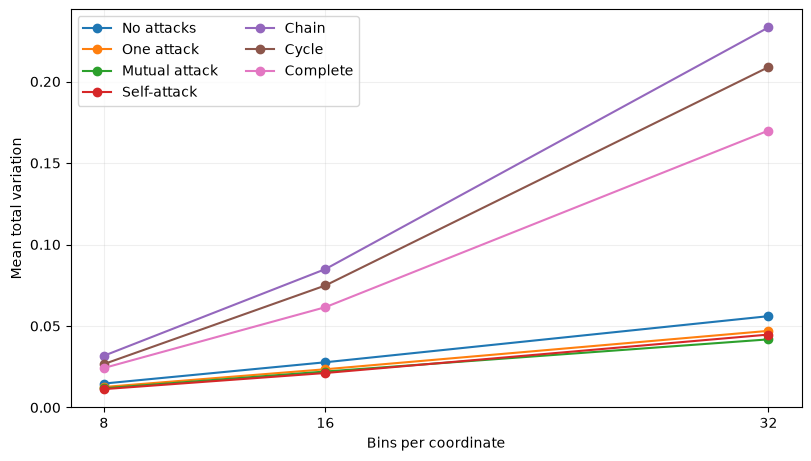

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for name in frameworks:
    means = stability[stability.Framework == name].groupby("Bins").TV.mean()
    ax.plot(means.index, means.values, "o-", label=name)
    
ax.set(xlabel="Bins per coordinate", ylabel="Mean total variation", xticks=[8, 16, 32], ylim=(0, None))
ax.legend(ncol=2)
ax.grid(alpha=0.2)
fig.savefig(OUT / "resampling.png", dpi=150)
plt.show()

## Observations

- With no attacks, scores equal weights and the density is roughly uniform.
- One attack reduces the target's score. Mutual attacks exclude joint high scores.
- A self-attack caps its score at $(\sqrt5-1)/2\approx0.618$.
- The three-argument examples produce different shapes. Complete mutual attack
  has the smallest hull volume among these examples.
- Broad density patterns persist across seeds. Finer bins give larger differences,
  especially in 3D, where the same sample count is spread over more cells.
- A stable convex hull does not guarantee an accurate attainable space.